# Expression patterns and exploratory patient groups

This notebook asks whether the six XGBoost genes describe a broader expression pattern, and whether TB-positive participants form reproducible groups. It follows [the model interpretation](gene_interactions_interpretation.ipynb); the [cohort and clinical notebook](gene_interactions_cohort_clinical.ipynb) tests the corresponding associations.

The six genes were selected using TB labels, so their heatmap and PCA are **descriptive views of selected features**. The broader analysis instead uses genes detected in at least 10% of training participants, ranks variance without TB labels, and fits scaling, PCA, UMAP, and cluster centers on training data. Test and validation participants are projected into those fixed representations. These are exploratory analyses of already examined cohorts, not a new untouched validation study.

All analyses use the main notebook's **training-reference VST**. This makes normalization consistent across splits; it differs from the split-specific VST used by the earlier GFS/XGBoost analysis. No classifier is refitted here.

In [1]:
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from umap import UMAP

SEED = 87
SPLITS = {"train": "Training", "test": "Test", "val": "Validation"}
SPLIT_MARKERS = {"train": "o", "test": "s", "val": "^"}
TB_COLORS = {"negative": "#386A87", "positive": "#AC4B75"}
COHORT_COLORS = {"GHL": "#386A87", "R2D2": "#B17A2A", "TBSQUARE": "#78917D"}
GENES = ["GBP5", "AHNAK", "JMJD1C", "MNDA", "LYZ", "SPI1"]
current = Path.cwd().resolve()
ROOT = next(path for path in [current, *current.parents]
            if (path / "Files_For_Manuscript/counts.train.tsv").is_file())
DATA = ROOT / "Files_For_Manuscript"
REFERENCE = DATA / "gene_interactions_reference"
OUTPUT = ROOT / "Figure_Output/Gene_Interactions/focused"
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "savefig.dpi": 300, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})


def save_figure(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"patterns_{name}.{suffix}", bbox_inches="tight")

/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load aligned expression and metadata

The main notebook exports the full expression matrix after applying the training normalization reference. Its manifest checks the source counts, metadata, and reference. The pooled differential-expression file supplies gene names only; its statistics are never used to choose features here.

RNA-source overlays reuse the existing plasma fractions from `Files_For_Manuscript/discovery_cell_types.tsv`, through the interpretation notebook's checked exports; all 251 participants are covered. `cto_wb.txt` contains distinct whole-blood estimates for an optional paired comparison, not the plasma overlay used here.

In [2]:
manifest = json.loads((REFERENCE / "expression_training_vst.json").read_text())
for relative_path, expected_hash in {**manifest["inputs"], **manifest["artifacts"]}.items():
    actual_hash = hashlib.sha256((ROOT / relative_path).read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f"Input changed: {relative_path}; rerun the main notebook export."
with np.load(REFERENCE / "expression_training_vst.npz", allow_pickle=False) as saved:
    expression = pd.DataFrame(saved["values"], index=saved["samples"], columns=saved["genes"])
metadata = pd.concat([
    pd.read_csv(DATA / f"metadata.{split}.tsv", sep="\t", index_col="sample_id").assign(split=split)
    for split in SPLITS
])
assert metadata.index.is_unique and expression.index.is_unique
assert set(expression.index) == set(metadata.index)
expression = expression.loc[metadata.index]
assert np.isfinite(expression.to_numpy()).all()
source_analysis = pd.read_csv(OUTPUT / "myeloid_analysis_inputs.csv", index_col="sample_id")
assert metadata[["split", "cohort", "tb"]].equals(source_analysis.loc[metadata.index, ["split", "cohort", "tb"]])
metadata["myeloid_fraction"] = source_analysis.loc[metadata.index, "myeloid_fraction"]
assert metadata.ftcount.gt(0).all()
metadata["log10_assigned_reads"] = np.log10(metadata.ftcount)
training = metadata.split.eq("train")
gene_names = pd.read_csv(DATA / "deseq_results.tsv", sep="\t", usecols=["gene_id", "gene_name"]).set_index("gene_id").gene_name
eligible_genes = pd.read_csv(REFERENCE / "eligible_genes.csv").gene_id
assert eligible_genes.is_unique and eligible_genes.isin(expression.columns).all()
six_ids = [gene_names.index[gene_names.eq(gene)].item() for gene in GENES]
six_expression = expression[six_ids].rename(columns=gene_names)
display(pd.crosstab([metadata.split, metadata.cohort], metadata.tb))

tb              negative  positive
split cohort                      
test  GHL             12        18
      R2D2            15        16
train GHL             24        39
      R2D2            33        34
val   TBSQUARE        25        35

## Six-gene heatmap

Each gene is centered and scaled using training participants. Columns are hierarchically ordered using the six genes across all participants **for visualization only**; that ordering does not enter PCA or patient-group fitting. The heatmap is clipped at ±3 training standard deviations for color display, while calculations retain the full values.

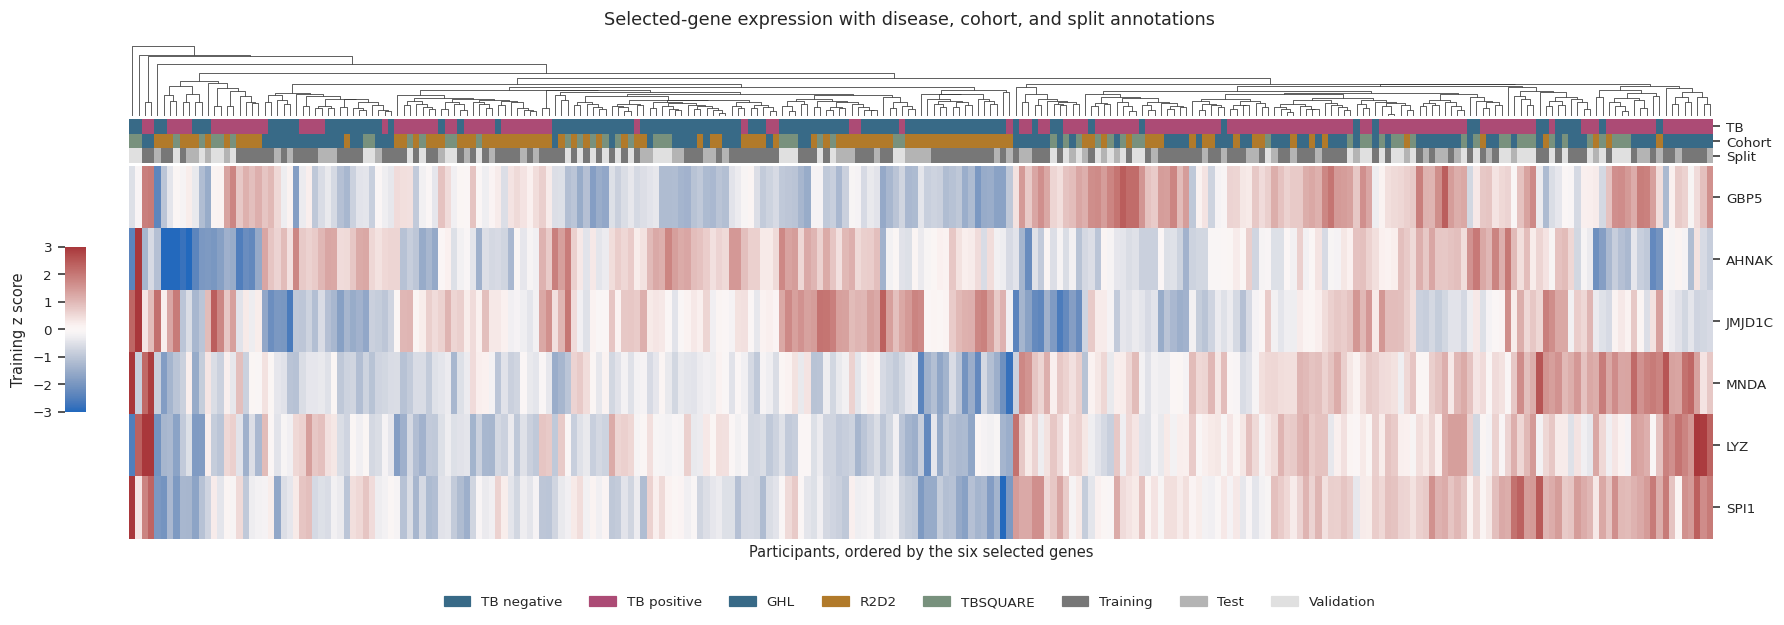

In [3]:
six_scaler = StandardScaler().fit(six_expression.loc[training])
six_scaled = pd.DataFrame(six_scaler.transform(six_expression), index=metadata.index, columns=GENES)
split_colors = {"train": "#777777", "test": "#B4B4B4", "val": "#E0E0E0"}
annotations = pd.DataFrame({
    "TB": metadata.tb.map(TB_COLORS),
    "Cohort": metadata.cohort.map(COHORT_COLORS),
    "Split": metadata.split.map(split_colors),
}, index=metadata.index)
heatmap = sns.clustermap(six_scaled.T, row_cluster=False, col_cluster=True,
                        method="average", metric="euclidean", col_colors=annotations,
                        cmap="vlag", center=0, vmin=-3, vmax=3, xticklabels=False,
                        figsize=(16, 5), dendrogram_ratio=(0.05, 0.15),
                        cbar_pos=(0.02, 0.3, 0.012, 0.3),
                        cbar_kws={"label": "Training z score"})
heatmap.cax.yaxis.set_label_position("left")
heatmap.cax.yaxis.tick_left()
heatmap.ax_heatmap.set(xlabel="Participants, ordered by the six selected genes", ylabel="")
heatmap.fig.suptitle("Selected-gene expression with disease, cohort, and split annotations", y=1.03)
legend = [Patch(color=color, label=f"TB {label}") for label, color in TB_COLORS.items()]
legend += [Patch(color=color, label=label) for label, color in COHORT_COLORS.items()]
legend += [Patch(color=color, label=SPLITS[label]) for label, color in split_colors.items()]
heatmap.fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=8, frameon=False)
save_figure(heatmap.fig, "six_gene_heatmap")
plt.show()
six_scaled.to_csv(OUTPUT / "patterns_six_gene_training_z.csv")

## PCA of six selected genes and a broader expression set

For the broad view, retain genes with at least 10 reads in at least 13 training participants (10% of 130), then take the 1,000 with highest training VST variance. Standardization and PCA use training samples only. Twenty principal components provide the fixed space used by UMAP and clustering; only PC1 and PC2 are plotted.

Color overlays show TB status, cohort, the previously estimated myeloid RNA fraction, and assigned-read depth. An apparent separation can reflect several of these variables together. Myeloid fractions come from the same RNA data and are not independent cell counts.

In [4]:
training_variance = expression.loc[training, eligible_genes].var().sort_values(ascending=False)
broad_genes = training_variance.head(1000).index
broad_scaler = StandardScaler().fit(expression.loc[training, broad_genes])
broad_scaled = broad_scaler.transform(expression[broad_genes])
with threadpool_limits(limits=1):
    broad_pca = PCA(n_components=20, svd_solver="full").fit(broad_scaled[training])
    broad_scores = broad_pca.transform(broad_scaled)
    six_pca = PCA(n_components=6, svd_solver="full").fit(six_scaled.loc[training])
    six_scores = six_pca.transform(six_scaled)
pc_columns = [f"PC{number}" for number in range(1, 21)]
pc_scores = pd.DataFrame(broad_scores, index=metadata.index, columns=pc_columns)
feature_table = training_variance.rename("training_variance").to_frame().join(gene_names)
feature_table["used_for_pca"] = feature_table.index.isin(broad_genes)
feature_table.to_csv(OUTPUT / "patterns_training_features.csv", index_label="gene_id")
pd.DataFrame(broad_pca.components_.T, index=broad_genes, columns=pc_columns).join(gene_names).to_csv(
    OUTPUT / "patterns_pca_loadings.csv", index_label="gene_id")
pc_scores.join(metadata[["split", "cohort", "tb"]]).to_csv(OUTPUT / "patterns_pca_scores.csv", index_label="sample_id")
variance_table = pd.DataFrame({"component": pc_columns,
                               "variance_explained": broad_pca.explained_variance_ratio_,
                               "cumulative_variance": broad_pca.explained_variance_ratio_.cumsum()})
variance_table.to_csv(OUTPUT / "patterns_pca_variance.csv", index=False)
display(variance_table.round(3))

,component,variance_explained,cumulative_variance
0,PC1,0.618,0.618
1,PC2,0.054,0.672
2,PC3,0.036,0.708
3,PC4,0.029,0.737
4,PC5,0.017,0.754
5,PC6,0.015,0.769
6,PC7,0.013,0.782
7,PC8,0.011,0.793
8,PC9,0.010,0.803
9,PC10,0.008,0.811


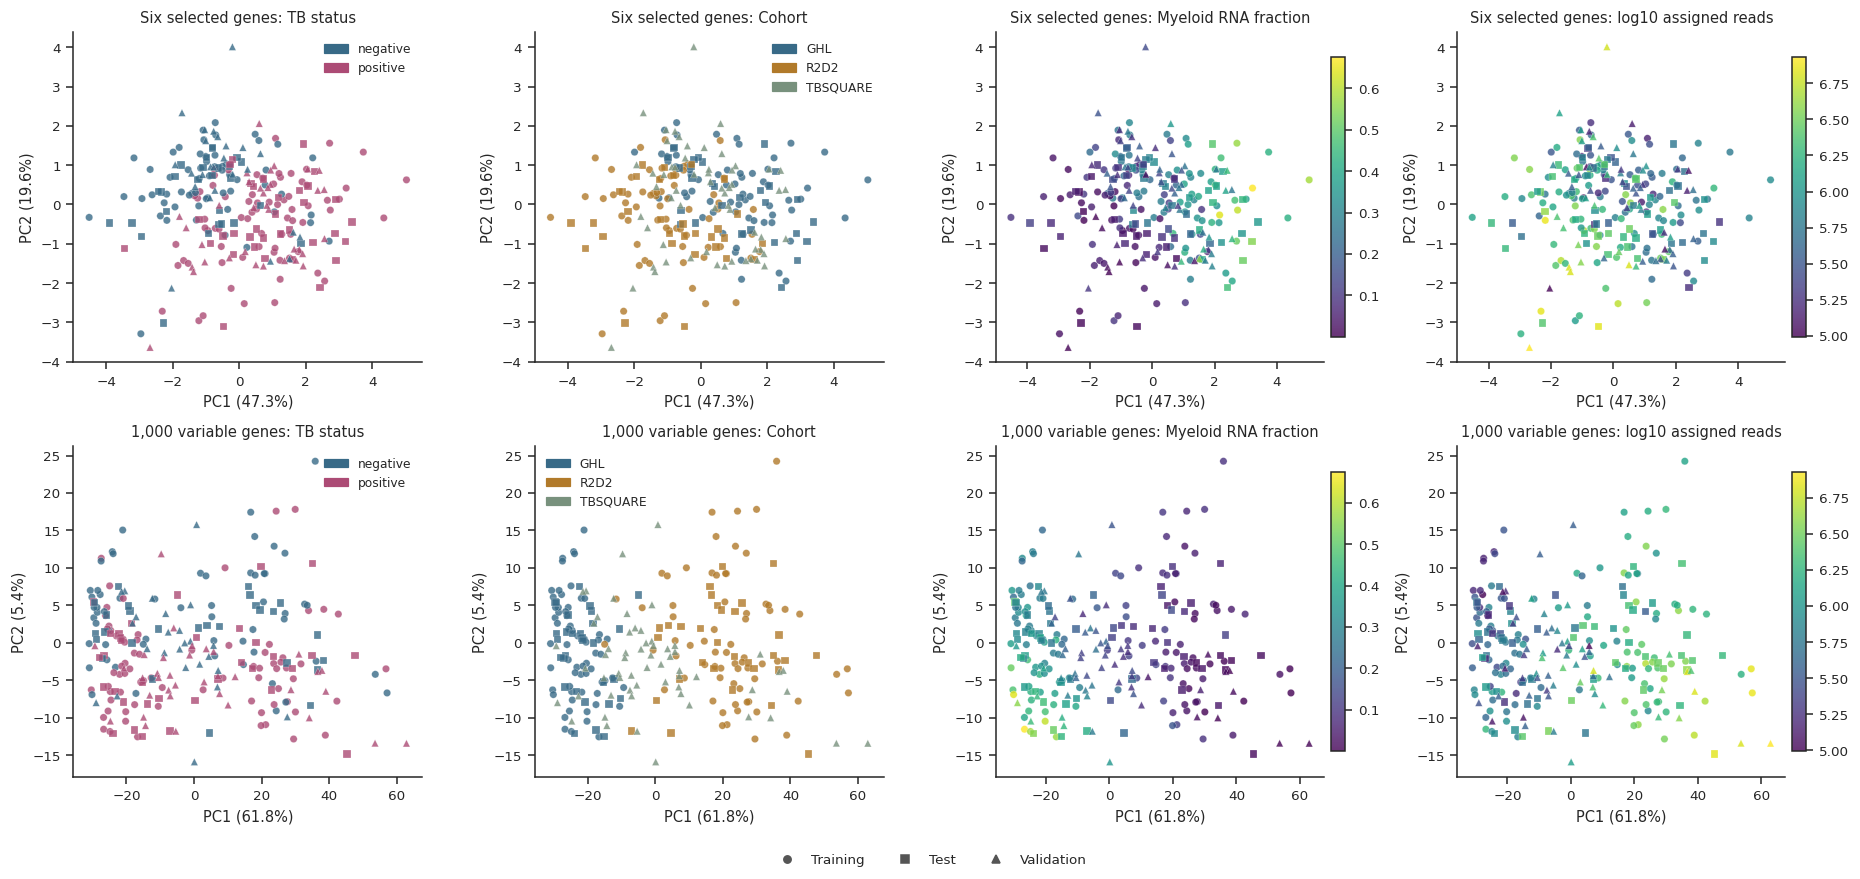

In [5]:
def plot_embedding(axis, coordinates, color_column, palette=None):
    """Plot one representation with fixed split markers and one color variable."""
    for split, marker in SPLIT_MARKERS.items():
        rows = metadata.split.eq(split).to_numpy()
        values = metadata.loc[rows, color_column]
        colors = values.map(palette) if palette else values
        scatter = axis.scatter(coordinates[rows, 0], coordinates[rows, 1],
                               c=colors, marker=marker, s=23, alpha=0.8,
                               edgecolors="white", linewidths=0.2,
                               **({} if palette else {"cmap": "viridis", "vmin": metadata[color_column].min(),
                                                       "vmax": metadata[color_column].max()}))
    if palette:
        handles = [Patch(color=color, label=label) for label, color in palette.items()]
        axis.legend(handles=handles, frameon=False, fontsize=8, loc="best")
    else:
        axis.figure.colorbar(scatter, ax=axis, fraction=0.04, pad=0.02)


color_overlays = [("tb", "TB status", TB_COLORS), ("cohort", "Cohort", COHORT_COLORS),
                  ("myeloid_fraction", "Myeloid RNA fraction", None),
                  ("log10_assigned_reads", "log10 assigned reads", None)]
figure, axes = plt.subplots(2, 4, figsize=(17, 8))
for row, (scores, pca, label) in enumerate([(six_scores, six_pca, "Six selected genes"),
                                          (broad_scores, broad_pca, "1,000 variable genes")]):
    for column, (variable, title, palette) in enumerate(color_overlays):
        axis = axes[row, column]
        plot_embedding(axis, scores, variable, palette)
        axis.set(title=f"{label}: {title}",
                 xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
                 ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
split_legend = [Line2D([], [], marker=marker, color="#555555", linestyle="", label=SPLITS[split])
                for split, marker in SPLIT_MARKERS.items()]
figure.legend(handles=split_legend, loc="lower center", ncol=3, frameon=False)
figure.tight_layout(rect=(0, 0.04, 1, 1))
save_figure(figure, "pca_overlays")
plt.show()

## UMAP as a complementary view

Fit UMAP on the 20 training PCs and transform the held-out participants. Neighborhood size 15, minimum distance 0.3, and seed 87 are prespecified, not chosen to maximize TB separation. A small sensitivity table varies neighborhood size and seed. Trustworthiness evaluates preservation of local neighbors, **not disease prediction or cluster validity**.

UMAP can distort density and create apparent gaps. Patient groups below are therefore fitted in the 20-PC space. See the official documentation on [transforming new data](https://umap-learn.readthedocs.io/en/latest/transform.html) and [clustering caveats](https://umap-learn.readthedocs.io/en/latest/clustering.html).

/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/local/workdir/amz63/cfRNA_TB/.venv/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


split            test  train    val
neighbors seed                     
10        87    0.938  0.943  0.884
15        87    0.941  0.943  0.857
          88    0.937  0.935  0.856
30        87    0.926  0.918  0.855

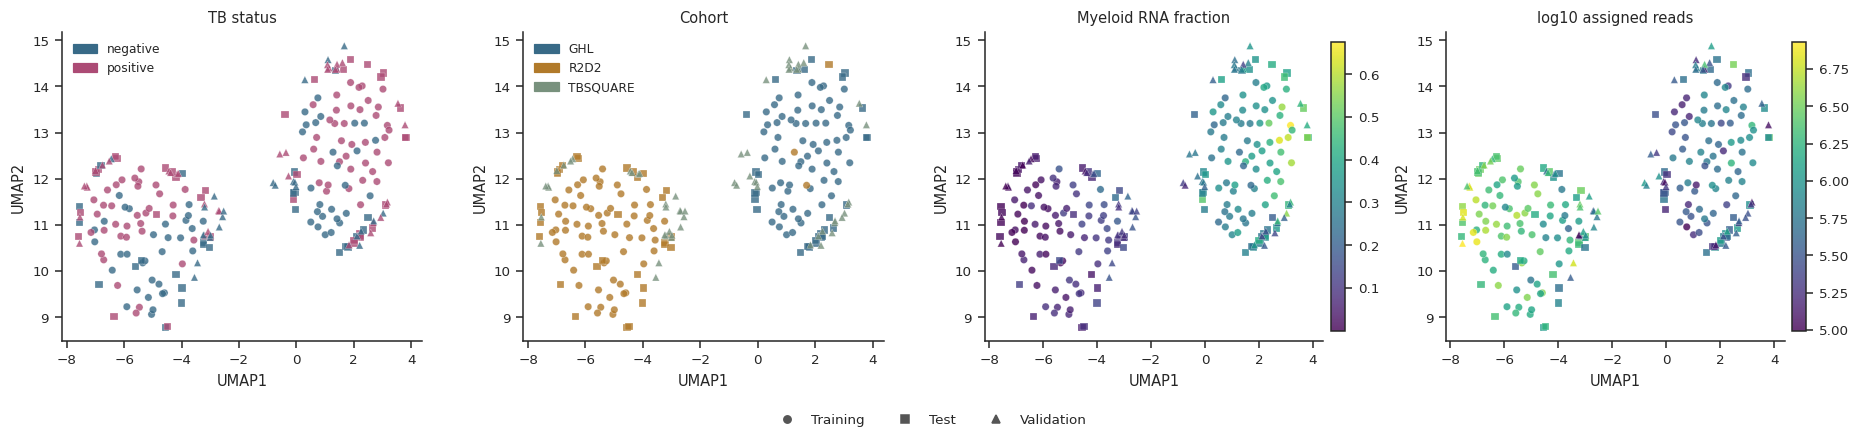

In [6]:
def fit_umap(neighbors, seed):
    reducer = UMAP(n_neighbors=neighbors, min_dist=0.3, random_state=seed,
                   transform_seed=seed, n_jobs=1)
    coordinates = np.empty((len(metadata), 2))
    coordinates[training] = reducer.fit_transform(broad_scores[training])
    for split in ["test", "val"]:
        rows = metadata.split.eq(split).to_numpy()
        coordinates[rows] = reducer.transform(broad_scores[rows])
    return coordinates


umap_coordinates = fit_umap(neighbors=15, seed=SEED)
quality_rows = []
for neighbors, seed in [(15, SEED), (10, SEED), (30, SEED), (15, SEED + 1)]:
    coordinates = umap_coordinates if (neighbors, seed) == (15, SEED) else fit_umap(neighbors, seed)
    for split in SPLITS:
        rows = metadata.split.eq(split).to_numpy()
        quality_rows.append({"neighbors": neighbors, "seed": seed, "split": split,
                             "trustworthiness_at_10_neighbors": trustworthiness(
                                 broad_scores[rows], coordinates[rows], n_neighbors=10)})
umap_quality = pd.DataFrame(quality_rows)
umap_quality.to_csv(OUTPUT / "patterns_umap_sensitivity.csv", index=False)
pd.DataFrame(umap_coordinates, index=metadata.index, columns=["UMAP1", "UMAP2"]).join(
    metadata[["split", "cohort", "tb"]]).to_csv(OUTPUT / "patterns_umap_scores.csv", index_label="sample_id")
display(umap_quality.pivot(index=["neighbors", "seed"], columns="split",
                           values="trustworthiness_at_10_neighbors").round(3))
figure, axes = plt.subplots(1, 4, figsize=(17, 4))
for axis, (variable, title, palette) in zip(axes, color_overlays):
    plot_embedding(axis, umap_coordinates, variable, palette)
    axis.set(title=title, xlabel="UMAP1", ylabel="UMAP2")
figure.legend(handles=split_legend, loc="lower center", ncol=3, frameon=False)
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "umap_overlays")
plt.show()

## Do TB-positive participants form stable groups?

Fit k-means to the 20-PC representation of **training TB-positive participants only**, for k = 2, 3, and 4. Choose the largest training silhouette score; this simple rule does not establish that a discrete subtype exists. Freeze the selected centers before assigning test and validation TB-positive participants.

Stability uses 100 bootstrap resamples of the training TB-positive participants. Each refit predicts labels for the original training participants; adjusted Rand index (ARI) compares those labels to the original fit, without requiring matching cluster numbers. Feature selection, scaling, and PCA stay fixed, so this is **conditional clustering stability**, not uncertainty for the entire pipeline. High stability alone can reflect reproducible cohort or technical structure.

In [7]:
tb_training = training & metadata.tb.eq("positive")
training_tb_scores = broad_scores[tb_training]
cluster_models = {}
stability_rows = []
bootstrap_rows = []
random = np.random.default_rng(SEED)
bootstrap_indices = [random.integers(0, len(training_tb_scores), len(training_tb_scores)) for _ in range(100)]
with threadpool_limits(limits=1):
    for cluster_count in [2, 3, 4]:
        model = KMeans(n_clusters=cluster_count, n_init=20, random_state=SEED).fit(training_tb_scores)
        cluster_models[cluster_count] = model
        agreement = []
        for replicate, indices in enumerate(bootstrap_indices, start=1):
            bootstrap_model = KMeans(n_clusters=cluster_count, n_init=20, random_state=SEED).fit(training_tb_scores[indices])
            ari = adjusted_rand_score(model.labels_, bootstrap_model.predict(training_tb_scores))
            agreement.append(ari)
            bootstrap_rows.append({"clusters": cluster_count, "replicate": replicate, "ari": ari})
        stability_rows.append({"clusters": cluster_count,
                               "training_silhouette": silhouette_score(training_tb_scores, model.labels_),
                               "bootstrap_ari_median": np.median(agreement),
                               "bootstrap_ari_p10": np.quantile(agreement, 0.1),
                               "bootstrap_ari_p90": np.quantile(agreement, 0.9),
                               "training_cohort_ari": adjusted_rand_score(metadata.loc[tb_training, "cohort"], model.labels_),
                               "smallest_training_cluster": np.bincount(model.labels_).min()})
pd.DataFrame(bootstrap_rows).to_csv(OUTPUT / "patterns_cluster_bootstraps.csv", index=False)
cluster_stability = pd.DataFrame(stability_rows)
selected_count = int(cluster_stability.loc[cluster_stability.training_silhouette.idxmax(), "clusters"])
cluster_stability["selected"] = cluster_stability.clusters.eq(selected_count)
cluster_stability.to_csv(OUTPUT / "patterns_cluster_stability.csv", index=False)
display(cluster_stability.round(3))
cluster_model = cluster_models[selected_count]
tb_rows = metadata.tb.eq("positive")
cluster_labels = pd.Series(cluster_model.predict(broad_scores[tb_rows]) + 1,
                           index=metadata.index[tb_rows], name="cluster")
cluster_data = metadata.loc[tb_rows].join(cluster_labels)
cluster_data["distance_to_center"] = cluster_model.transform(broad_scores[tb_rows]).min(axis=1)
cluster_data.to_csv(OUTPUT / "patterns_cluster_assignments.csv", index_label="sample_id")

,clusters,training_silhouette,bootstrap_ari_median,bootstrap_ari_p10,bootstrap_ari_p90,training_cohort_ari,smallest_training_cluster,selected
0,2,0.547,1.000,0.945,1.000,0.945,33,True
1,3,0.414,0.861,0.752,0.951,0.780,9,False
2,4,0.202,0.608,0.502,0.729,0.553,9,False


## Check cohort, clinical, and technical context

These summaries describe the frozen groups without testing dozens of post hoc associations. Xpert categories are shown only where recorded; missing values remain missing. All participants here are TB positive. Distances to training centers help identify weak transfer; merely assigning a held-out participant to the closest center is not evidence that the same population subtype replicated.

participants  myeloid_fraction_median  assigned_reads_median  \
split cluster                                                                 
test  1                  21                    0.375               620585.0   
      2                  13                    0.052              2204954.0   
train 1                  40                    0.352               599294.5   
      2                  33                    0.053              2443742.0   
val   1                  20                    0.267               335152.5   
      2                  15                    0.035              2366257.0   

               age_median  hiv_positive  center_distance_median  
split cluster                                                    
test  1              29.0             3                  13.042  
      2              37.0             1                  13.338  
train 1              29.5             5                  13.406  
      2              35.0             2                  14.140  
val   1              30.0             6                  17.220  
      2              30.0             1                  20.518

cohort         GHL  R2D2  TBSQUARE
split cluster                     
test  1         18     3         0
      2          0    13         0
train 1         39     1         0
      2          0    33         0
val   1          0     0        20
      2          0     0        15

semiquant      High  Low  Medium  Missing
split cluster                            
test  1           7    7       5        2
      2           9    1       3        0
train 1          14   10      11        5
      2          10    6      17        0
val   1           7    5       8        0
      2           6    3       6        0

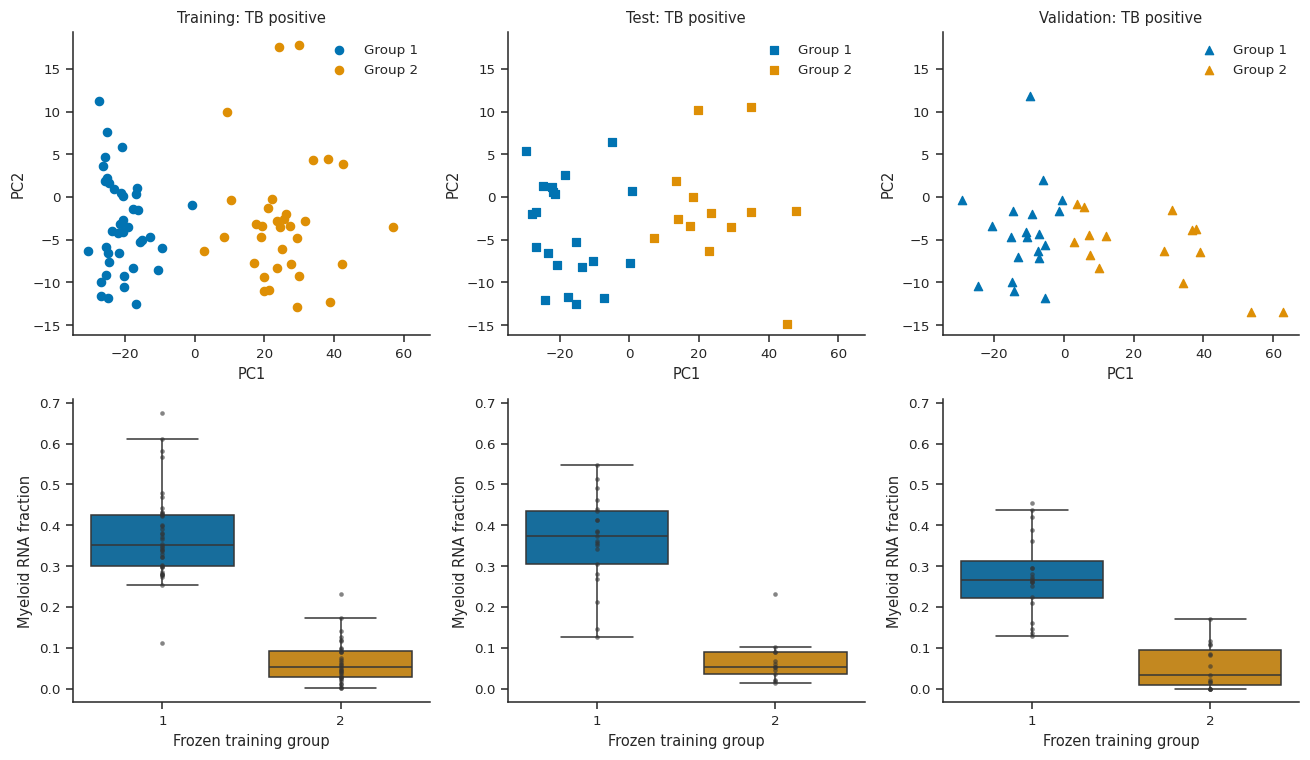

In [8]:
cluster_summary = cluster_data.groupby(["split", "cluster"], observed=True).agg(
    participants=("tb", "size"), myeloid_fraction_median=("myeloid_fraction", "median"),
    assigned_reads_median=("ftcount", "median"), age_median=("age", "median"),
    hiv_positive=("hiv", lambda values: values.eq("Positive").sum()),
    center_distance_median=("distance_to_center", "median"))
cluster_summary.to_csv(OUTPUT / "patterns_cluster_characteristics.csv")
cohort_counts = pd.crosstab([cluster_data.split, cluster_data.cluster], cluster_data.cohort)
cohort_counts.to_csv(OUTPUT / "patterns_cluster_cohorts.csv")
burden_counts = pd.crosstab([cluster_data.split, cluster_data.cluster], cluster_data.semiquant.fillna("Missing"))
burden_counts.to_csv(OUTPUT / "patterns_cluster_xpert.csv")
display(cluster_summary.round(3), cohort_counts, burden_counts)

cluster_palette = dict(zip(range(1, selected_count + 1), sns.color_palette("colorblind", selected_count)))
figure, axes = plt.subplots(2, 3, figsize=(12, 7))
for column, (split, title) in enumerate(SPLITS.items()):
    participants = cluster_data.index[cluster_data.split.eq(split)]
    for cluster, color in cluster_palette.items():
        members = participants[cluster_labels.loc[participants].eq(cluster)]
        scores = pc_scores.loc[members]
        axes[0, column].scatter(scores.PC1, scores.PC2, c=[color], s=30,
                                marker=SPLIT_MARKERS[split], label=f"Group {cluster}")
    axes[0, column].set(title=f"{title}: TB positive", xlabel="PC1", ylabel="PC2")
    axes[0, column].legend(frameon=False)
    sns.boxplot(data=cluster_data.loc[participants], x="cluster", y="myeloid_fraction",
                hue="cluster", palette=cluster_palette, legend=False, ax=axes[1, column],
                order=list(cluster_palette), hue_order=list(cluster_palette), fliersize=0)
    sns.stripplot(data=cluster_data.loc[participants], x="cluster", y="myeloid_fraction",
                  color="#333333", size=3, alpha=0.6, ax=axes[1, column], order=list(cluster_palette), jitter=False)
    axes[1, column].set(xlabel="Frozen training group", ylabel="Myeloid RNA fraction")
# Use common axes so projection differences remain visible across splits.
for row in range(2):
    limits = [axis.get_ylim() for axis in axes[row]]
    for axis in axes[row]:
        axis.set_ylim(min(limit[0] for limit in limits), max(limit[1] for limit in limits))
x_limits = [axis.get_xlim() for axis in axes[0]]
for axis in axes[0]:
    axis.set_xlim(min(limit[0] for limit in x_limits), max(limit[1] for limit in x_limits))
figure.tight_layout()
save_figure(figure, "patient_groups")
plt.show()

## Reading these results

Use the broad PCA overlays to decide whether apparent structure follows disease, cohort, myeloid RNA contribution, or read depth. The six-gene heatmap describes model-selected features and cannot independently validate their biological relevance. UMAP is a visualization, and its gaps are not evidence of cell states or patient subtypes.

The stability table and cohort counts are the key checks for the patient groups. Small groups, low bootstrap agreement, strong cohort alignment, or large held-out distances weaken a subtype interpretation. Clinical and pathway follow-ups provide more direct tests of the proposed myeloid/TB explanation. The [optional gene-excluded deconvolution check](gene_interactions_deconvolution.ipynb) examines one source of circularity; these completed patterns do not depend on it. Neither the existing fractions nor that check can distinguish changing RNA release from changing cell abundance.

**Current result:** the two training groups are stable but almost reproduce cohort membership: one contains all 39 GHL TB-positive participants and one R2D2 participant; the other contains 33 R2D2 participants (cohort ARI 0.945). Their median myeloid RNA contributions are 35.2% and 5.3%, and assigned-read depth also differs. UMAP shows the same broad cohort/composition structure. These results do **not** establish TB subtypes. Validation participants can be assigned to both centers, but assignment alone does not validate those groups biologically.

In [9]:
chosen = cluster_stability.loc[cluster_stability.selected].iloc[0]
display(Markdown(
    f"**Run summary:** {len(eligible_genes):,} genes passed the training detection filter; "
    f"the broad view uses {len(broad_genes):,}. The first 20 PCs explain "
    f"{broad_pca.explained_variance_ratio_.sum():.1%} of standardized training variance. "
    f"The training silhouette rule selected **{selected_count} groups** "
    f"(silhouette {chosen.training_silhouette:.3f}; median conditional-bootstrap ARI "
    f"{chosen.bootstrap_ari_median:.3f}, 10th–90th percentiles "
    f"{chosen.bootstrap_ari_p10:.3f}–{chosen.bootstrap_ari_p90:.3f}; "
    f"cohort ARI {chosen.training_cohort_ari:.3f}). "
    "These quantities describe structure and stability; they are not evidence of a validated TB subtype."
))
provenance = {"normalization": manifest["normalization"], "input_sha256": manifest["inputs"],
              "seed": SEED, "training_detection_filter": "count >= 10 in >= 13 training participants",
              "eligible_genes": len(eligible_genes), "pca_genes": len(broad_genes),
              "pca_components": 20, "selected_clusters": selected_count, "bootstrap_replicates": 100,
              "versions": {package: version(package) for package in ["numpy", "pandas", "scikit-learn", "umap-learn", "seaborn"]}}
(OUTPUT / "patterns_provenance.json").write_text(json.dumps(provenance, indent=2))

**Run summary:** 11,279 genes passed the training detection filter; the broad view uses 1,000. The first 20 PCs explain 86.3% of standardized training variance. The training silhouette rule selected **2 groups** (silhouette 0.547; median conditional-bootstrap ARI 1.000, 10th–90th percentiles 0.945–1.000; cohort ARI 0.945). These quantities describe structure and stability; they are not evidence of a validated TB subtype.

1273